   fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
0            7.4              0.70         0.00             1.9      0.076   
1            7.8              0.88         0.00             2.6      0.098   
2            7.8              0.76         0.04             2.3      0.092   
3           11.2              0.28         0.56             1.9      0.075   
4            7.4              0.70         0.00             1.9      0.076   

   free sulfur dioxide  total sulfur dioxide  density    pH  sulphates  \
0                 11.0                  34.0   0.9978  3.51       0.56   
1                 25.0                  67.0   0.9968  3.20       0.68   
2                 15.0                  54.0   0.9970  3.26       0.65   
3                 17.0                  60.0   0.9980  3.16       0.58   
4                 11.0                  34.0   0.9978  3.51       0.56   

   alcohol  quality  
0      9.4        5  
1      9.8        5  
2      9.8        5 

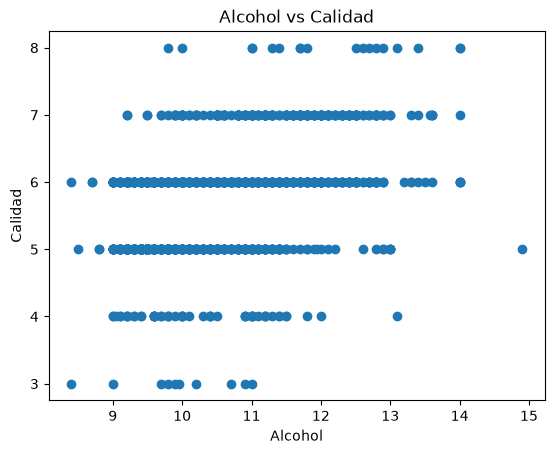


Matriz X:
[[1.  9.4]
 [1.  9.8]
 [1.  9.8]
 [1.  9.8]
 [1.  9.4]]

X^T:
[[ 1.   1.   1.  ...  1.   1.   1. ]
 [ 9.4  9.8  9.8 ... 11.  10.2 11. ]]

X^T X:
[[  1599.          16666.35      ]
 [ 16666.35       175527.84916667]]

(X^T X)^-1:
[[ 0.06048912 -0.00574344]
 [-0.00574344  0.00055104]]

X^T y:
[ 9012.         94586.76666667]

Beta:
[1.87497489 0.36084177]

Pendiente m: 0.360841765334996
Intersección b: 1.8749748869976202

Ecuación:
y = 0.3608x + 1.8750

Primeras predicciones:
[5.26688748 5.41122419 5.41122419 5.41122419 5.26688748 5.26688748
 5.26688748 5.48339254 5.30297166 5.66381342]

Primeros errores:
[-0.26688748 -0.41122419 -0.41122419  0.58877581 -0.26688748 -0.26688748
 -0.26688748  1.51660746  1.69702834 -0.66381342]

Primeros errores cuadrados:
[0.07122893 0.16910533 0.16910533 0.34665696 0.07122893 0.07122893
 0.07122893 2.30009819 2.87990519 0.44064826]

MSE:
0.5039840256714571


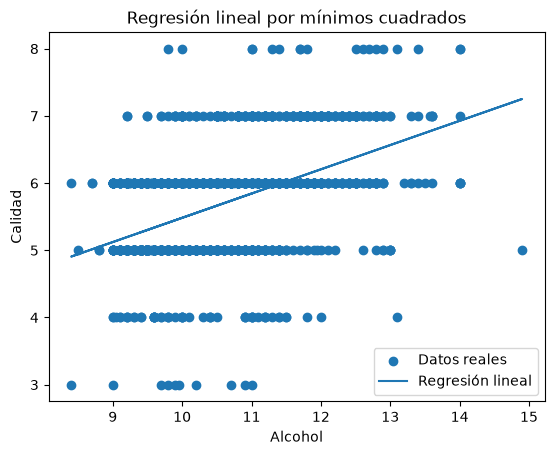

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("winequality-red.csv", sep=";")

print(df.head())
print("\nTamaño:", df.shape)

# X = alcohol
# y = calidad del vino

X = df["alcohol"].values
y = df["quality"].values

plt.scatter(X, y)

plt.xlabel("Alcohol")
plt.ylabel("Calidad")
plt.title("Alcohol vs Calidad")

plt.show()

X_matriz = np.column_stack((
    np.ones(len(X)),
    X
))

print("\nMatriz X:")
print(X_matriz[:5])


X_T = X_matriz.T

print("\nX^T:")
print(X_T)

XTX = X_T @ X_matriz

print("\nX^T X:")
print(XTX)

XTX_inv = np.linalg.inv(XTX)

print("\n(X^T X)^-1:")
print(XTX_inv)

XTy = X_T @ y

print("\nX^T y:")
print(XTy)


beta = XTX_inv @ XTy

print("\nBeta:")
print(beta)

b = beta[0]
m = beta[1]

print("\nPendiente m:", m)
print("Intersección b:", b)

print(f"\nEcuación:")
print(f"y = {m:.4f}x + {b:.4f}")



# 11. PREDICCIONES


y_pred = m * X + b

print("\nPrimeras predicciones:")
print(y_pred[:10])



# 12. ERROR


errores = y - y_pred

print("\nPrimeros errores:")
print(errores[:10])



# 13. ERROR CUADRÁTICO


errores_cuadrados = errores ** 2

print("\nPrimeros errores cuadrados:")
print(errores_cuadrados[:10])



# 14. MSE


mse = np.mean(errores_cuadrados)

print("\nMSE:")
print(mse)



# 15. GRAFICAR RECTA


plt.scatter(X, y, label="Datos reales")
plt.plot(X, y_pred, label="Regresión lineal")

plt.xlabel("Alcohol")
plt.ylabel("Calidad")
plt.title("Regresión lineal por mínimos cuadrados")

plt.legend()
plt.show()